# Machine Learning -- Jour
## Matplolib & seaborn : voir avant 
- Maitriser histogramme et nuage de points avec Matplotlib 
- Maitriser boxplot

## 1. Le problème 

On e entrainé un modèle au jour2 sans jamais avoir regardé  à quoi ressemblent les données. COmmment sont reparties les notes ? les étudiants réussisent se distinguent t'ils visuellement de ceux qui échouent ? 

## 2. Première tentative  : uniquement des chiffres 

In [86]:
import pandas as pd 
df = pd.read_csv("notes_etudiants.csv")
print(df[["note_maths" , "note_info"]].describe())

        note_maths    note_info
count  5000.000000  5000.000000
mean     10.985032    11.996466
std       3.997952     3.459939
min       0.000000     0.000000
25%       8.270000     9.660000
50%      10.990000    12.030000
75%      13.750000    14.320000
max      20.000000    20.000000


**A retenir: les statistiques résument les données , mais seul un graphique montre leur forme réelle. 

## 3. Matplotlib : histogramme 

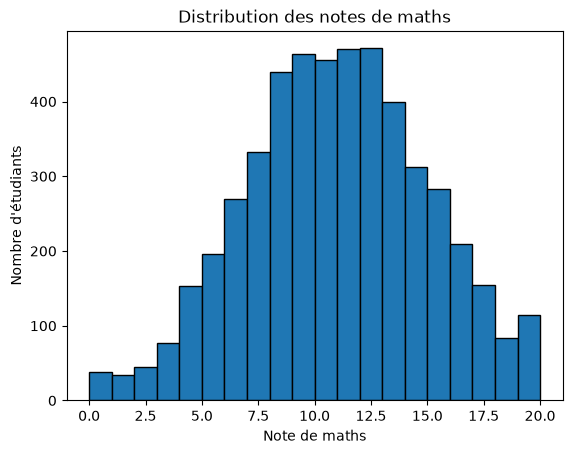

In [87]:
import matplotlib.pyplot as plt
fig , ax = plt.subplots()
ax.hist(df["note_maths"] , bins = 20  ,edgecolor = "black" )
ax.set_xlabel("Note de maths")
ax.set_ylabel("Nombre d'étudiants")
ax.set_title("Distribution des notes de maths")
plt.show()

## 4. Matplotlib : nuage de points

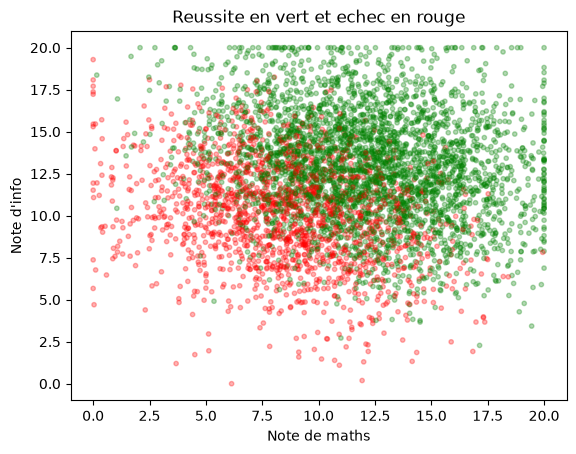

In [88]:
df["note_physique"] = df["note_physique"].fillna(df["note_physique"].mean())
df["moyenne_generale"] = df[["note_maths" , "note_info" , "note_physique" ]].mean(axis = 1)
df["reussite"] = (df["moyenne_generale"] >=10).map({True : "green" , False : "red"})
fig , ax = plt.subplots()
ax.scatter(df["note_maths" ] , df["note_info"] , c=df["reussite"] , alpha = 0.3 , s=10)
ax.set_xlabel("Note de maths")
ax.set_ylabel("Note d'info")
ax.set_title("Reussite en vert et echec en rouge")
plt.show()

# 5. Seaborn : boxplot

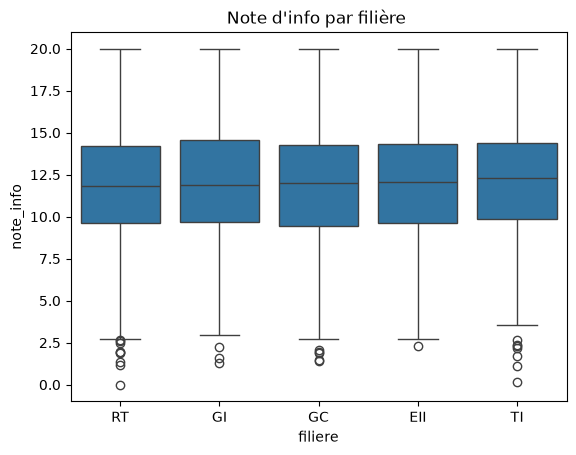

In [89]:
import seaborn as sns
import numpy as np

fig, ax = plt.subplots()
sns.boxplot(data = df , x = 'filiere' , y='note_info' , ax = ax)
ax.set_title("Note d'info par filière ")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

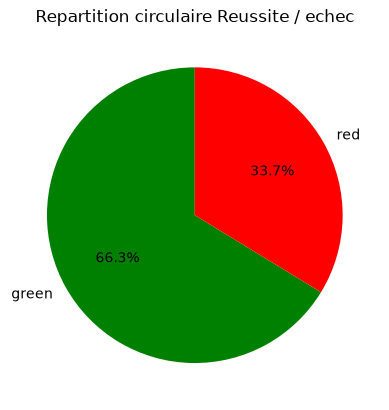

In [90]:
effectifs= df["reussite"].value_counts()
plt.pie(effectifs, 
        labels=effectifs.index,
        autopct="%1.1f%%",
        startangle=90,
        colors=["green", "red"])
plt.title("Repartition circulaire Reussite / echec")
plt.show

Diagramme circulaire

<function matplotlib.pyplot.show(close=None, block=None)>

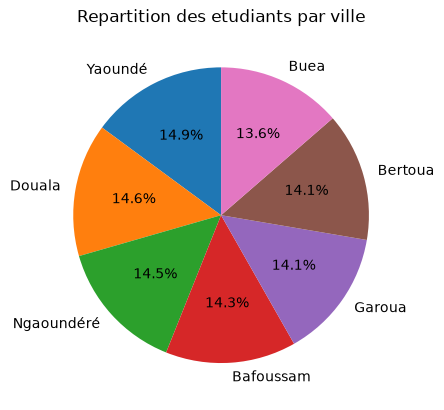

In [91]:
effectifs= df["ville"].value_counts()
plt.pie(effectifs, 
        labels=effectifs.index,
        autopct="%1.1f%%",
        startangle=90)
plt.title("Repartition des etudiants par ville")
plt.show

Diagramme semi circulaire

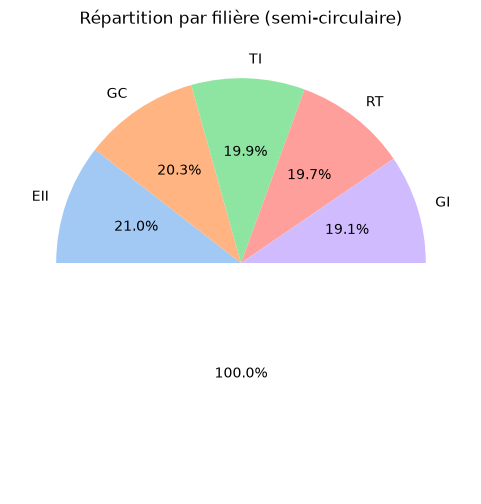

In [92]:
repartition = df["filiere"].value_counts()
valeurs = list(repartition.values) + [sum(repartition.values)]  # moitié fictive
labels = list(repartition.index) + [""]
couleurs = list(sns.color_palette("pastel"))[:len(repartition)] + ["white"]

fig, ax = plt.subplots(figsize=(6,6))
wedges, texts, autotexts = ax.pie(
    valeurs, labels=labels, colors=couleurs,
    startangle=180, counterclock=False,
    autopct=lambda p: f"{p*2:.1f}%" if p > 0 else ""
)
# on masque le texte de la moitié fictive
for i in range(len(repartition), len(texts)):
    texts[i].set_visible(False)

plt.title("Répartition par filière (semi-circulaire)")
plt.show()

Boîte à moustaches (boxplot) pour les 3 notes

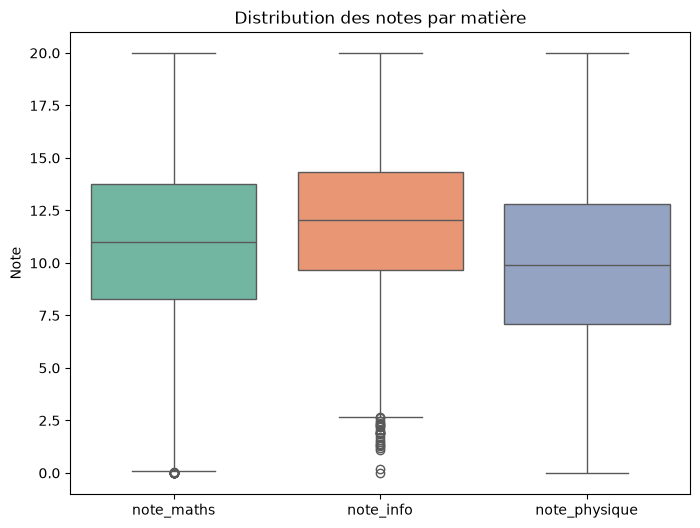

In [93]:
notes = df[["note_maths", "note_info", "note_physique"]]

plt.figure(figsize=(8,6))
sns.boxplot(data=notes, palette="Set2")
plt.title("Distribution des notes par matière")
plt.ylabel("Note")
plt.show()

Polygones des fréquences (les 3 notes sur le même graphe)

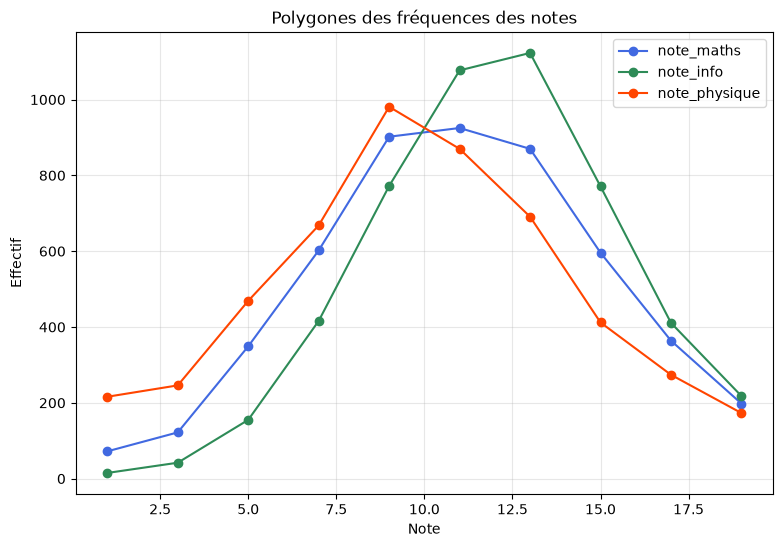

In [94]:
plt.figure(figsize=(9,6))

for col, couleur in zip(["note_maths", "note_info", "note_physique"], 
                         ["royalblue", "seagreen", "orangered"]):
    counts, bin_edges = np.histogram(df[col], bins=10)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    plt.plot(bin_centers, counts, marker="o", label=col, color=couleur)

plt.title("Polygones des fréquences des notes")
plt.xlabel("Note")
plt.ylabel("Effectif")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Courbe de tendance

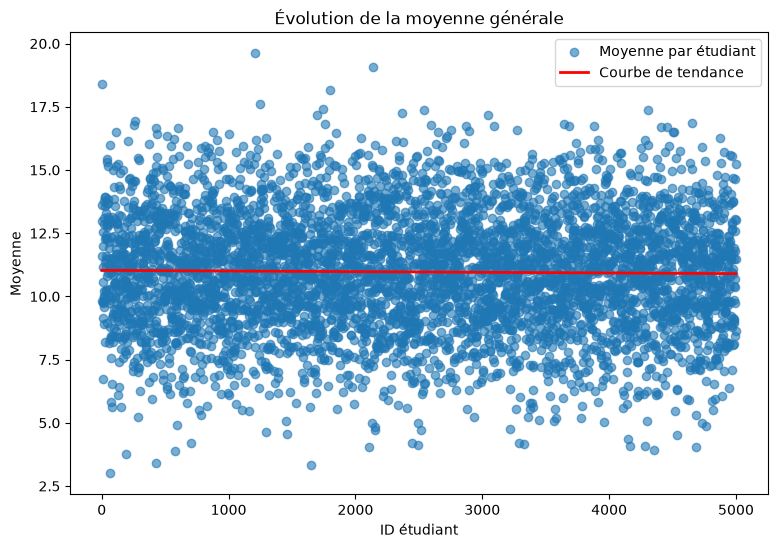

In [95]:
df["moyenne"] = df[["note_maths", "note_info", "note_physique"]].mean(axis=1)
df_sorted = df.sort_values("id")

x = df_sorted["id"]
y = df_sorted["moyenne"]

# régression linéaire simple
coeffs = np.polyfit(x, y, deg=1)
tendance = np.poly1d(coeffs)

plt.figure(figsize=(9,6))
plt.scatter(x, y, alpha=0.6, label="Moyenne par étudiant")
plt.plot(x, tendance(x), color="red", linewidth=2, label="Courbe de tendance")
plt.title("Évolution de la moyenne générale")
plt.xlabel("ID étudiant")
plt.ylabel("Moyenne")
plt.legend()
plt.show()

Graphique radar

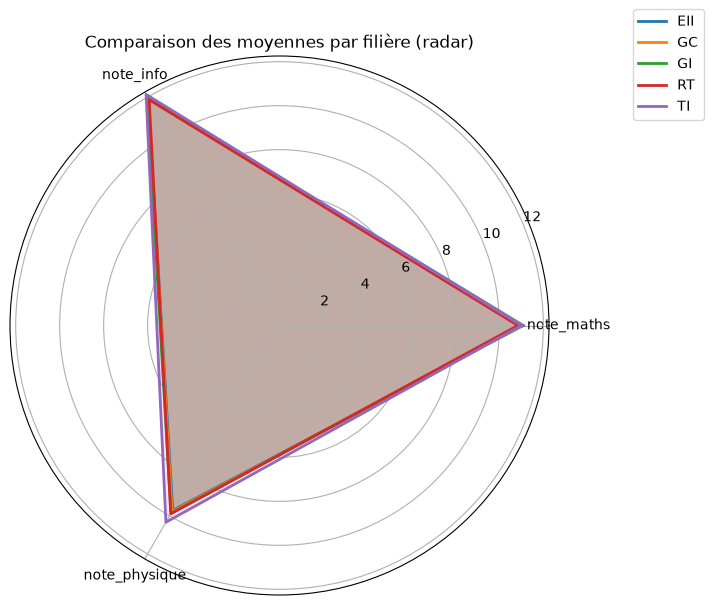

In [96]:
moyennes_filiere = df.groupby("filiere")[["note_maths", "note_info", "note_physique"]].mean()

categories = list(moyennes_filiere.columns)
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]  # fermer le cercle

fig, ax = plt.subplots(figsize=(7,7), subplot_kw=dict(polar=True))

for filiere in moyennes_filiere.index:
    valeurs = moyennes_filiere.loc[filiere].tolist()
    valeurs += valeurs[:1]
    ax.plot(angles, valeurs, linewidth=2, label=filiere)
    ax.fill(angles, valeurs, alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)
ax.set_title("Comparaison des moyennes par filière (radar)")
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
plt.show()

## 6. Seaborn: heatmap de correlation

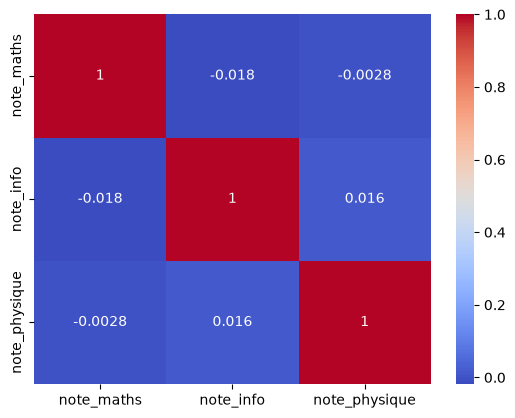

In [97]:
correlations = df[["note_maths", "note_info", "note_physique"]].corr()
fig, ax = plt.subplots()
sns.heatmap(correlations, annot=True, cmap="coolwarm", ax=ax)
plt.show()

** A retenir** :
- Toujours visualiser une variable avant de la resumer par un seul chiffre

# Devoir a faire

Histogramme de note_maths et note_physique

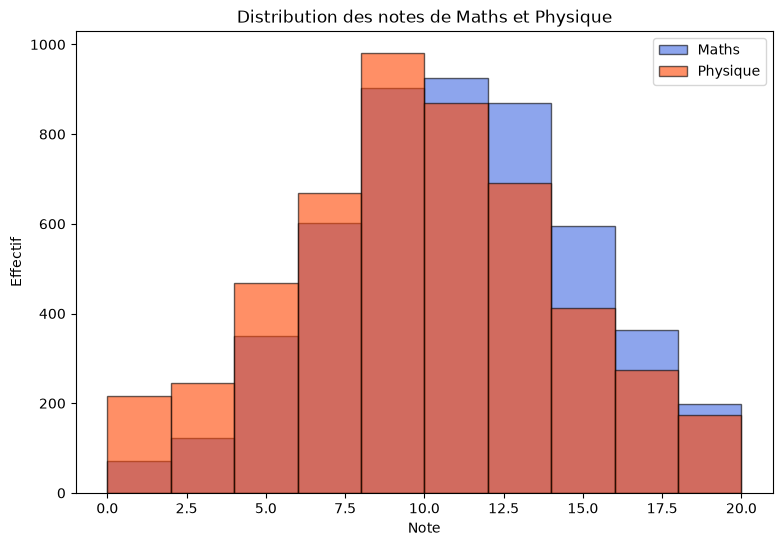

In [98]:
plt.figure(figsize=(9,6))
plt.hist(df["note_maths"], bins=10, alpha=0.6, label="Maths", color="royalblue", edgecolor="black")
plt.hist(df["note_physique"], bins=10, alpha=0.6, label="Physique", color="orangered", edgecolor="black")
plt.title("Distribution des notes de Maths et Physique")
plt.xlabel("Note")
plt.ylabel("Effectif")
plt.legend()
plt.show()

Boxplot de note_maths et note_info par filière

/tmp/ipykernel_4384/3103491120.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="filiere", y="note_maths", palette="Set2", ax=axes[0])
/tmp/ipykernel_4384/3103491120.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="filiere", y="note_info", palette="Set2", ax=axes[1])


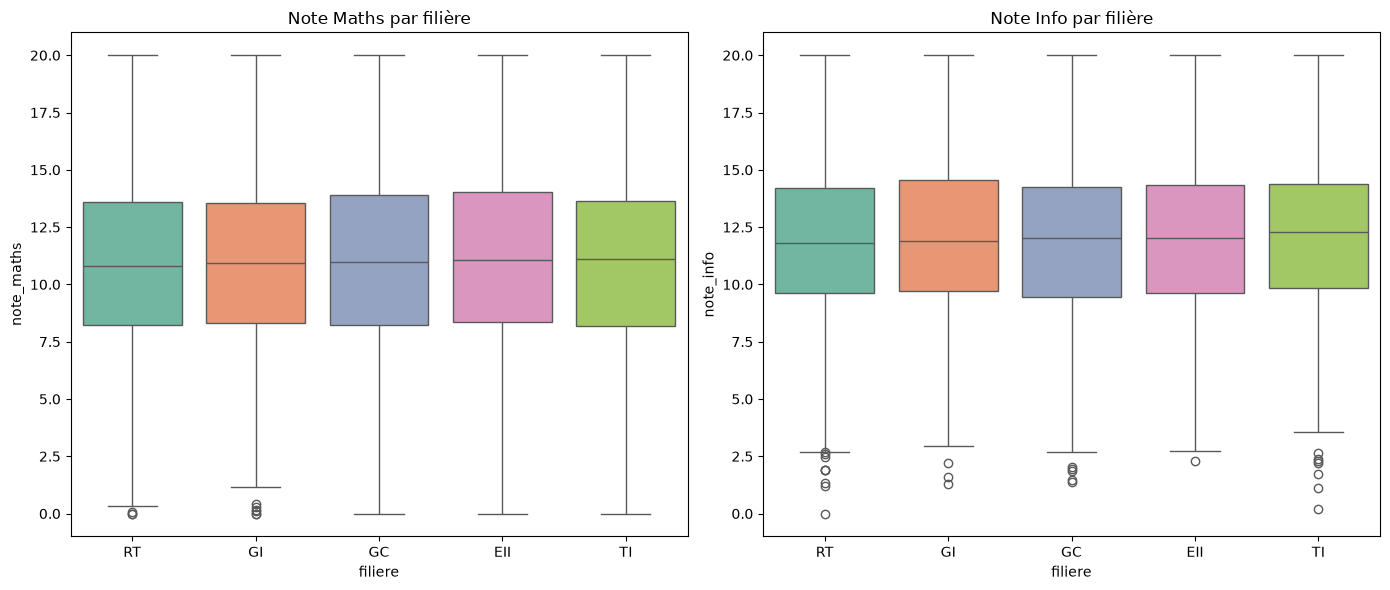

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(14,6))

sns.boxplot(data=df, x="filiere", y="note_maths", palette="Set2", ax=axes[0])
axes[0].set_title("Note Maths par filière")

sns.boxplot(data=df, x="filiere", y="note_info", palette="Set2", ax=axes[1])
axes[1].set_title("Note Info par filière")

plt.tight_layout()
plt.show()

Nuage de points note_maths vs note_physique, coloré par réussite

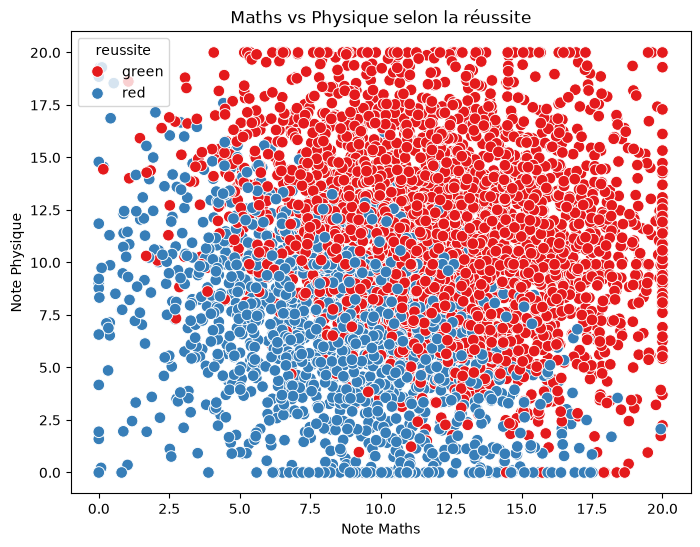

In [100]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x="note_maths", y="note_physique", hue="reussite", palette="Set1", s=70)
plt.title("Maths vs Physique selon la réussite")
plt.xlabel("Note Maths")
plt.ylabel("Note Physique")
plt.show()

Heatmap de corrélation des trois notes

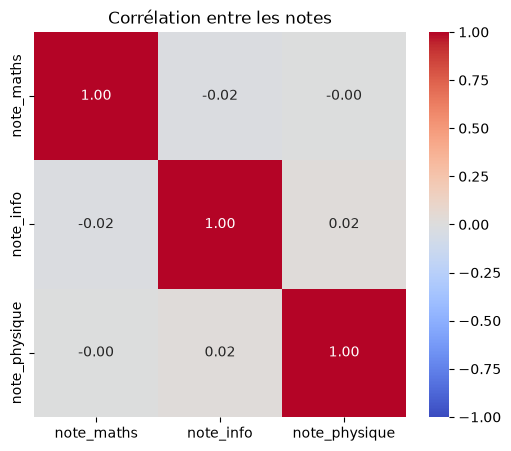

In [101]:
correlation = df[["note_maths", "note_info", "note_physique"]].corr()

plt.figure(figsize=(6,5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Corrélation entre les notes")
plt.show()

# Exercice d'application (autonomie)

## Deux histogrammes superposés (réussite vs échec)

Méthode avec seaborn (la plus simple) :

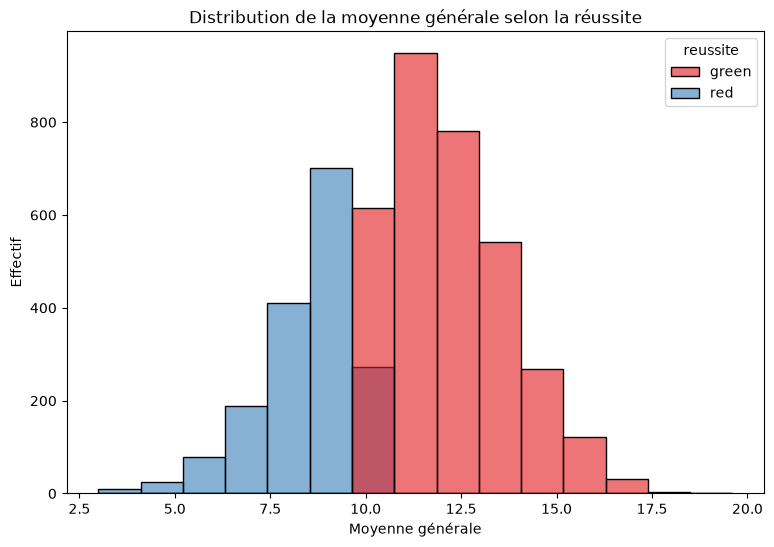

In [102]:
plt.figure(figsize=(9,6))
sns.histplot(data=df, x="moyenne_generale", hue="reussite", bins=15, alpha=0.6, palette="Set1")
plt.title("Distribution de la moyenne générale selon la réussite")
plt.xlabel("Moyenne générale")
plt.ylabel("Effectif")
plt.show()

Méthode avec ax.hist (deux appels manuels) :

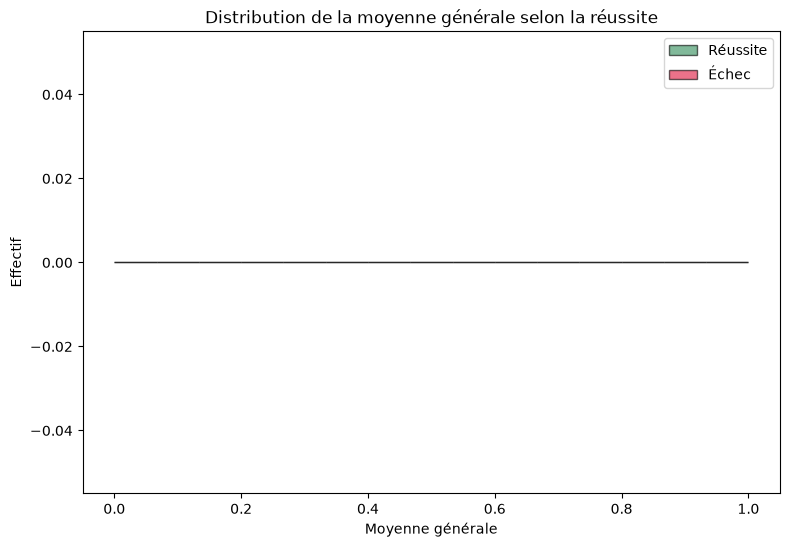

In [103]:
fig, ax = plt.subplots(figsize=(9,6))

ax.hist(df[df["reussite"] == True]["moyenne_generale"], bins=15, alpha=0.6, 
        label="Réussite", color="seagreen", edgecolor="black")
ax.hist(df[df["reussite"] == False]["moyenne_generale"], bins=15, alpha=0.6, 
        label="Échec", color="crimson", edgecolor="black")

ax.set_title("Distribution de la moyenne générale selon la réussite")
ax.set_xlabel("Moyenne générale")
ax.set_ylabel("Effectif")
ax.legend()
plt.show()

Pairplot

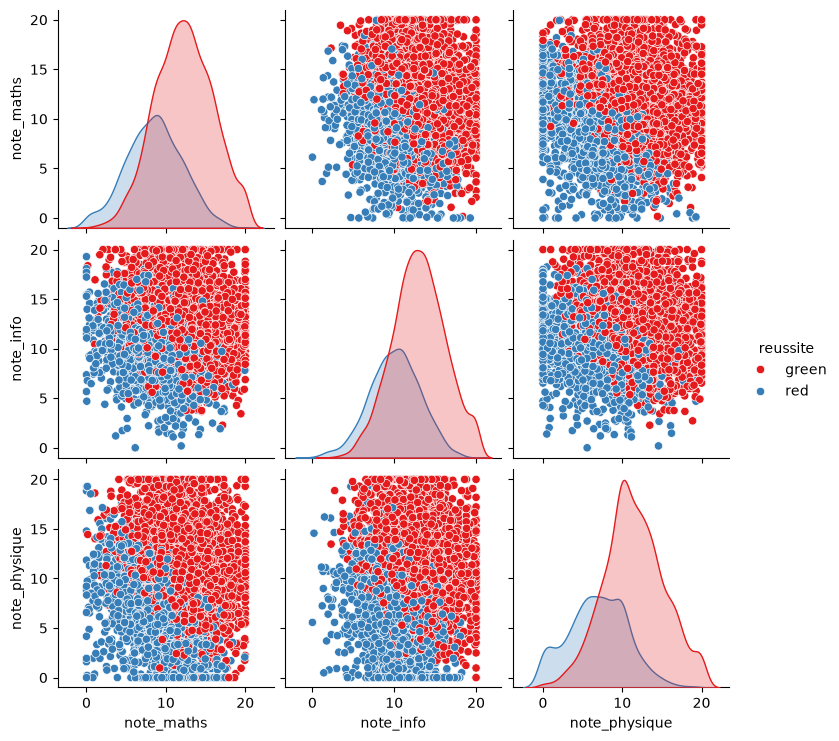

In [104]:
sns.pairplot(df[["note_maths", "note_info", "note_physique", "reussite"]], hue="reussite", palette="Set1")
plt.show()

Sauvegarder un graphique

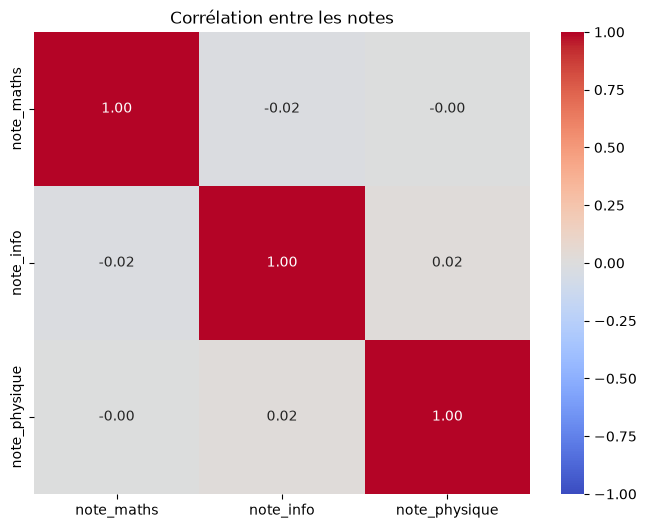

In [105]:
plt.figure(figsize=(8,6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Corrélation entre les notes")
plt.savefig("mon_graphique.png", dpi=150, bbox_inches="tight")
plt.show()